# Monitor the Live AQI


In [1]:
import json

from vayuayan import (
    CPCBLive,
    get_aqi_category,
    health_impact,
    live_metrics,
)

## 1. Get Your Location


In [2]:
# Initialize the Live AQI client
client = CPCBLive()

# Get your location
lat, lon = client.get_system_location()
# IP geolocation is approximate, so 1 decimal (about 11 km) is enough
print(f"Your approximate location: {lat:.1f}, {lon:.1f}")

Your approximate location: 19.1, 72.9


## 2. Find the Nearest Monitoring Station


In [3]:
# Find the nearest station
nearest_station = client.get_nearest_station()
print("Nearest Monitoring Station:")

# Keep the station ID for later
station_id = nearest_station[0]
station_name = nearest_station[1]
print(f"\nMonitoring Station ID: {station_id}")
print(f"Station Name: {station_name}")

Nearest Monitoring Station:

Monitoring Station ID: site_5104
Station Name: Kurla, Mumbai - MPCB


## 3. Get the Current Air Quality Data


In [4]:
# Get current AQI data
aqi_data = client.get_live_aqi_data(station_id=station_id)

print(f"Current Air Quality at {station_name}:")
metrics = live_metrics(aqi_data)
if metrics.empty:
    print("No data available, possibly due to station being offline.")
else:
    print(metrics.to_string(index=False, na_rep="NA"))

Current Air Quality at Kurla, Mumbai - MPCB:
pollutant  avg  min  max              period
    PM2.5  107   59  267 18-10-2026 14:00:00
     PM10  115   76  176 18-10-2026 14:00:00
      NO2    9    9    9 18-10-2026 14:00:00
      NH3    2    2    2 18-10-2026 14:00:00
      SO2   29   29   30 18-10-2026 14:00:00
       CO   25   25   25 18-10-2026 14:00:00
    OZONE   28   28   29 18-10-2026 14:00:00


## 4. Recent 15-Minute History

The live feed gives the latest reading only. For a time series, download the
station's 15-minute raw data with `CPCBHistorical`. The example below plots the
last 3 days of PM2.5 and PM10 for the station found above.

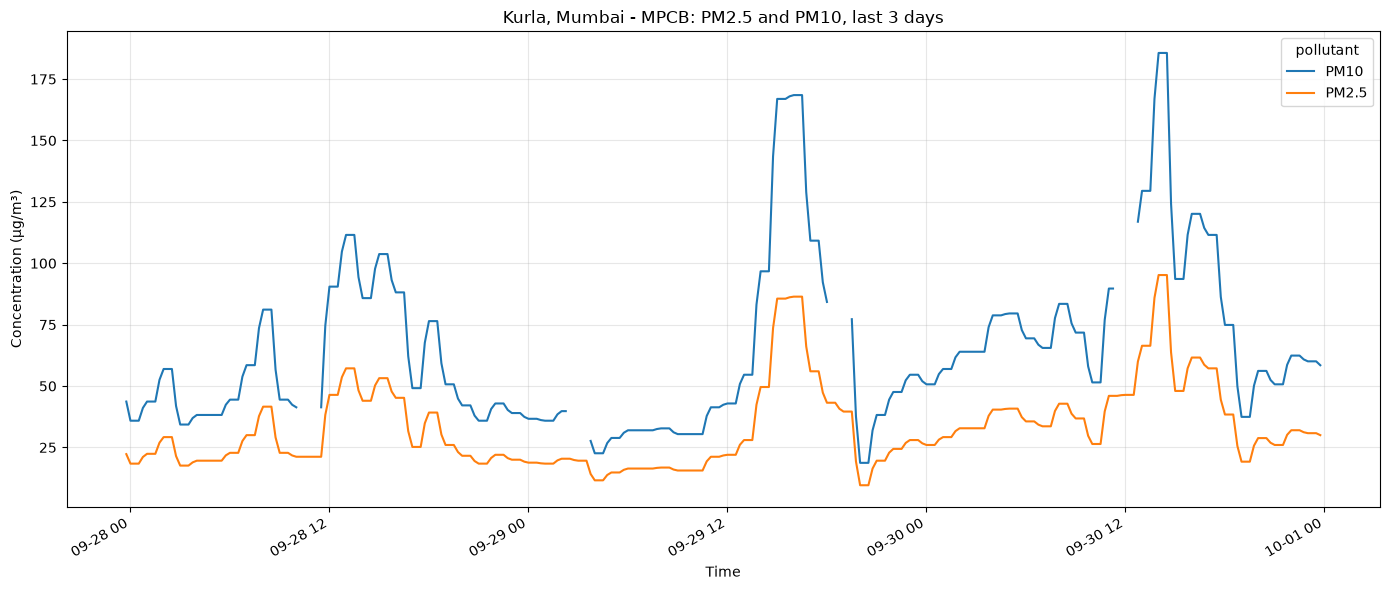

            min    max  mean
pollutant                   
PM10       18.7  185.6  64.5
PM2.5       9.6   95.2  33.0


In [5]:
import matplotlib.pyplot as plt
import pandas as pd

from vayuayan import CPCBHistorical

# Download this year's 15-minute raw data for the station found above
history = CPCBHistorical()
raw = history.download_raw_aqi_data_station_level(station_id, "2026", "", tidy=True)

# Keep PM2.5 and PM10, and the last 3 days that CPCB has published
pm = raw[raw["pollutant"].isin(["PM2.5", "PM10"])]
window_start = raw["timestamp"].max() - pd.Timedelta(days=3)
recent = pm[pm["timestamp"] >= window_start]

if recent.empty:
    print("No recent 15-minute data for this station.")
else:
    series = recent.pivot(index="timestamp", columns="pollutant", values="value")
    ax = series.plot(figsize=(14, 6))
    ax.set_title(f"{station_name}: PM2.5 and PM10, last 3 days")
    ax.set_xlabel("Time")
    ax.set_ylabel("Concentration (µg/m³)")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # The min, max and mean of each pollutant over the window
    print(recent.groupby("pollutant")["value"].agg(["min", "max", "mean"]).round(1))

## 5. AQI Category and Health Effect

In [6]:
# The AQI category and CPCB's possible health impact of the current AQI
aqi_value = (aqi_data.get("aqi") or aqi_data.get("airQualityIndex") or {}).get("value")

if aqi_value is None:
    print("The current AQI is not available.")
else:
    aqi_value = float(aqi_value)
    print(f"Current AQI: {aqi_value:.0f}")
    print(f"Category: {get_aqi_category(aqi_value)}")
    print(f"Possible health impact: {health_impact(aqi_value)}")

Current AQI: 115
Category: Moderate
Possible health impact: Breathing discomfort to the people with lung, heart disease, children and older adults


## 6. Get the AQI for Specific Coordinates


In [7]:
# Example: Get AQI for Mumbai coordinates
mumbai_lat = 19.0760
mumbai_lon = 72.8777

coords = (mumbai_lat, mumbai_lon)

# Find the station that is nearest to these coordinates
mumbai_station = client.get_nearest_station(coords=coords)
print("Nearest station to Mumbai:")
print(json.dumps(mumbai_station, indent=2))

# Get the AQI data for this location
mumbai_aqi = client.get_live_aqi_data(coords=coords)
mumbai_aqi.pop("last_hours", None)  # Remove last_hours to make the output short
print("\nCurrent AQI in Mumbai:")
print(json.dumps(mumbai_aqi, indent=2))

Nearest station to Mumbai:
[
  "site_5104",
  "Kurla, Mumbai - MPCB"
]

Current AQI in Mumbai:
{
  "station_id": "site_5104",
  "station_name": "Kurla, Mumbai - MPCB",
  "lastUpdate": "18-10-2026 14:00:00",
  "airQualityIndex": {
    "value": "115"
  },
  "metrics": [
    {
      "name": "PM2.5",
      "avg": "107",
      "min": "59",
      "max": "267",
      "avgDesc": "18-10-2026 14:00:00"
    },
    {
      "name": "PM10",
      "avg": "115",
      "min": "76",
      "max": "176",
      "avgDesc": "18-10-2026 14:00:00"
    },
    {
      "name": "NO2",
      "avg": "9",
      "min": "9",
      "max": "9",
      "avgDesc": "18-10-2026 14:00:00"
    },
    {
      "name": "NH3",
      "avg": "2",
      "min": "2",
      "max": "2",
      "avgDesc": "18-10-2026 14:00:00"
    },
    {
      "name": "SO2",
      "avg": "29",
      "min": "29",
      "max": "30",
      "avgDesc": "18-10-2026 14:00:00"
    },
    {
      "name": "CO",
      "avg": "25",
      "min": "25",
      "max": "25